# ML4 — Evaluation on held-out purchases

**Project:** DS 5020 Mini-Project "Customers Like You".

Inputs (read-only): `A_log.npz`, `A_binary.npz`, `customer_index.parquet`, `product_index.parquet`,
`test_targets.parquet`. Code: `src/evaluate.py`, which reuses the recommenders in `src/recommend.py` unchanged.

**Evaluation set.** The 1,931 evaluation customers from DE3, each mapped to its matrix row. A customer's targets are
**all** their new-product purchases in the test period, including the ones whose product is not in the matrix
(`in_matrix == False`): those are unwinnable, but they stay in the denominator for honesty.

**Metrics** (per customer, then averaged, reported in %):

- hit@10 = 1 if at least one target is in the top 10
- recall@10 = |top10 ∩ targets| / |targets|
- precision@10 = |top10 ∩ targets| / 10

Recommendations already exclude products bought in train, consistent with targets being new products only.

**Configurations.** `TruncatedSVD(randomized, n_iter=7, random_state=42)` fitted on `A_log` only;
k ∈ {20, 50, 100} × weighting ∈ {V, VSigma} × scoring row ∈ {log, binary} = 12 configs, plus the best-seller baseline.

**No winner is picked in code.** Everything is printed sorted by recall@10. The configuration with the highest
recall@10 is used for the follow-up analyses only (bootstrap, breakdowns, timing) because they need *a* reference.

In [1]:
# Environment guard: this notebook must run in the "giftlane" conda env (pandas 3.0.6).
# It fails fast with "Wrong Python environment. Run: conda activate giftlane" otherwise.
import sys
from pathlib import Path

_ROOT = Path.cwd().resolve()
if _ROOT.name == "notebooks":
    _ROOT = _ROOT.parent
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))

from src.env_check import check_env

print("environment OK:", check_env())

environment OK: /opt/homebrew/Caskroom/miniforge/base/envs/giftlane/bin/python


## 0. Setup and inputs

In [2]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import sklearn

from src.svd import load_inputs
from src.evaluate import (
    HISTORY_BUCKETS, K_GRID, RARE_BAND, ROW_SOURCES, TOP_N, WEIGHTINGS,
    breakdown_by_history, build_eval_set, evaluate_baseline, history_sizes, paired_bootstrap,
    rare_product_hits, run_grid, time_nightly,
)

ROOT = _ROOT
PROCESSED = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
FIG_DIR = REPORTS / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

A_log, product_index, customer_index = load_inputs(ROOT)
A_binary = sp.load_npz(PROCESSED / "A_binary.npz").tocsr()
targets = pd.read_parquet(PROCESSED / "test_targets.parquet")
assert A_binary.shape == A_log.shape and A_binary.nnz == A_log.nnz
assert np.array_equal(A_binary.indptr, A_log.indptr) and np.array_equal(A_binary.indices, A_log.indices)

print("python  :", sys.executable)
print("sklearn :", sklearn.__version__, "| numpy :", np.__version__, "| pandas :", pd.__version__)
print(f"A_log / A_binary : {A_log.shape[0]:,} x {A_log.shape[1]:,}, nnz {A_log.nnz:,} (identical sparsity pattern)")
print(f"test_targets     : {len(targets):,} rows, columns {list(targets.columns)}")

python  : /opt/homebrew/Caskroom/miniforge/base/envs/giftlane/bin/python
sklearn : 1.9.1 | numpy : 2.4.6 | pandas : 3.0.6
A_log / A_binary : 5,471 x 3,687, nnz 413,706 (identical sparsity pattern)
test_targets     : 49,647 rows, columns ['Customer ID', 'StockCode', 'seen_in_train', 'in_matrix']


## 1. Evaluation set

Targets are stored as a sparse boolean matrix `T` (evaluation customers × products) for the in-matrix targets, plus
the full target count per customer for the recall denominator.

In [3]:
ev = build_eval_set(targets, customer_index, product_index)
print(f"evaluation customers            : {ev.n_eval:,}")
print(f"target pairs (all)              : {int(ev.n_targets.sum()):,}   -> recall denominators")
print(f"target pairs in matrix          : {ev.T.nnz:,}   ({100 * ev.T.nnz / ev.n_targets.sum():.2f}%)")
print(f"reachable customers (>=1 in-matrix target): {int(ev.reachable.sum()):,}  ->  hit@10 ceiling = {ev.ceiling_pct:.2f}%")
print(f"targets per customer: mean {ev.n_targets.mean():.2f}, median {np.median(ev.n_targets):.0f}")
assert ev.n_eval == 1931 and int(ev.reachable.sum()) == 1913 and ev.T.nnz == 44922

evaluation customers            : 1,931
target pairs (all)              : 49,647   -> recall denominators
target pairs in matrix          : 44,922   (90.48%)
reachable customers (>=1 in-matrix target): 1,913  ->  hit@10 ceiling = 99.07%
targets per customer: mean 25.71, median 17


## 2. The 12 SVD configurations + baseline

One SVD fit per k (on `A_log`). `VSigma` reuses the same fit with a different scaling of the product vectors; the
`binary` scoring row takes the customer's row from `A_binary` instead of `A_log` (same sparsity pattern, so the
already-bought mask is unchanged).

In [4]:
results, per_cust, all_recs, base_recs = run_grid(
    A_log, A_binary, product_index, ev, ks=K_GRID, weightings=WEIGHTINGS, row_sources=ROW_SOURCES, n=TOP_N, verbose=True
)
base_row, base_pc, base_recs_arr = evaluate_baseline(base_recs[K_GRID[0]], ev, n=TOP_N)
print(f"{base_row['config']:<24} hit@10 {base_row['hit@10']:6.2f}%  recall@10 {base_row['recall@10']:6.2f}%  "
      f"precision@10 {base_row['precision@10']:6.2f}%")
per_cust[base_row["config"]] = base_pc
all_recs[base_row["config"]] = base_recs_arr

SVD k=20 V log           hit@10  18.85%  recall@10   1.66%  precision@10   2.64%  (fit 0.073s)


SVD k=20 V binary        hit@10  16.73%  recall@10   1.45%  precision@10   2.39%  (fit 0.073s)


SVD k=20 VSigma log      hit@10  16.31%  recall@10   1.20%  precision@10   2.12%  (fit 0.073s)


SVD k=20 VSigma binary   hit@10  14.91%  recall@10   1.10%  precision@10   1.92%  (fit 0.073s)


SVD k=50 V log           hit@10  21.44%  recall@10   2.35%  precision@10   3.15%  (fit 0.114s)


...

SVD k=100 V log          hit@10  22.68%  recall@10   2.44%  precision@10   3.41%  (fit 0.192s)


SVD k=100 V binary       hit@10  21.49%  recall@10   2.32%  precision@10   3.24%  (fit 0.192s)


SVD k=100 VSigma log     hit@10  21.80%  recall@10   1.99%  precision@10   3.06%  (fit 0.192s)


SVD k=100 VSigma binary  hit@10  19.73%  recall@10   1.74%  precision@10   2.76%  (fit 0.192s)


best-seller baseline     hit@10  26.77%  recall@10   1.74%  precision@10   3.62%


## 3. Results table, sorted by recall@10

Saved to `reports/ml4_results.csv`. `hit@10_reachable` restricts hit@10 to the 1,913 customers with at least one
in-matrix target; the ceiling for hit@10 over all 1,931 is 99.07%.

In [5]:
table = pd.concat([results, pd.DataFrame([base_row])], ignore_index=True)
table = table.sort_values(["recall@10", "hit@10"], ascending=False).reset_index(drop=True)
cols = ["config", "hit@10", "recall@10", "precision@10", "hit@10_reachable", "fit_s"]
print(table[cols].to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print(f"\nhit@10 ceiling (customers with >= 1 reachable target): {ev.ceiling_pct:.2f}%")
table.to_csv(REPORTS / "ml4_results.csv", index=False)
print("saved -> reports/ml4_results.csv")

best_name = results.sort_values(["recall@10", "hit@10"], ascending=False)["config"].iloc[0]
best_row = results.set_index("config").loc[best_name]
print(f"\nreference SVD config for the follow-up analyses (highest recall@10 among SVD configs): {best_name}")
print(f"  SVD      : hit@10 {best_row['hit@10']:.2f}%  recall@10 {best_row['recall@10']:.2f}%  precision@10 {best_row['precision@10']:.2f}%")
print(f"  baseline : hit@10 {base_row['hit@10']:.2f}%  recall@10 {base_row['recall@10']:.2f}%  precision@10 {base_row['precision@10']:.2f}%")

                 config  hit@10  recall@10  precision@10  hit@10_reachable  fit_s
        SVD k=100 V log  22.683      2.441         3.408            22.896  0.192
         SVD k=50 V log  21.440      2.351         3.154            21.641  0.114
      SVD k=50 V binary  20.145      2.331         3.045            20.335  0.114
     SVD k=100 V binary  21.491      2.323         3.242            21.694  0.192
   SVD k=100 VSigma log  21.802      1.989         3.061            22.007  0.192
   best-seller baseline  26.774      1.739         3.620            27.026  0.000
SVD k=100 VSigma binary  19.731      1.739         2.760            19.916  0.192
         SVD k=20 V log  18.850      1.662         2.641            19.028  0.073
    SVD k=50 VSigma log  19.057      1.661         2.589            19.237  0.114
 SVD k=50 VSigma binary  17.711      1.471         2.403            17.878  0.114
      SVD k=20 V binary  16.727      1.450         2.393            16.884  0.073
    SVD k=20 VSi

### Bar chart

hit@10 and recall@10 for the baseline and all 12 configurations (ordered as in the table). Saved to
`reports/figures/ml4_results.png`.

saved -> reports/figures/ml4_results.png


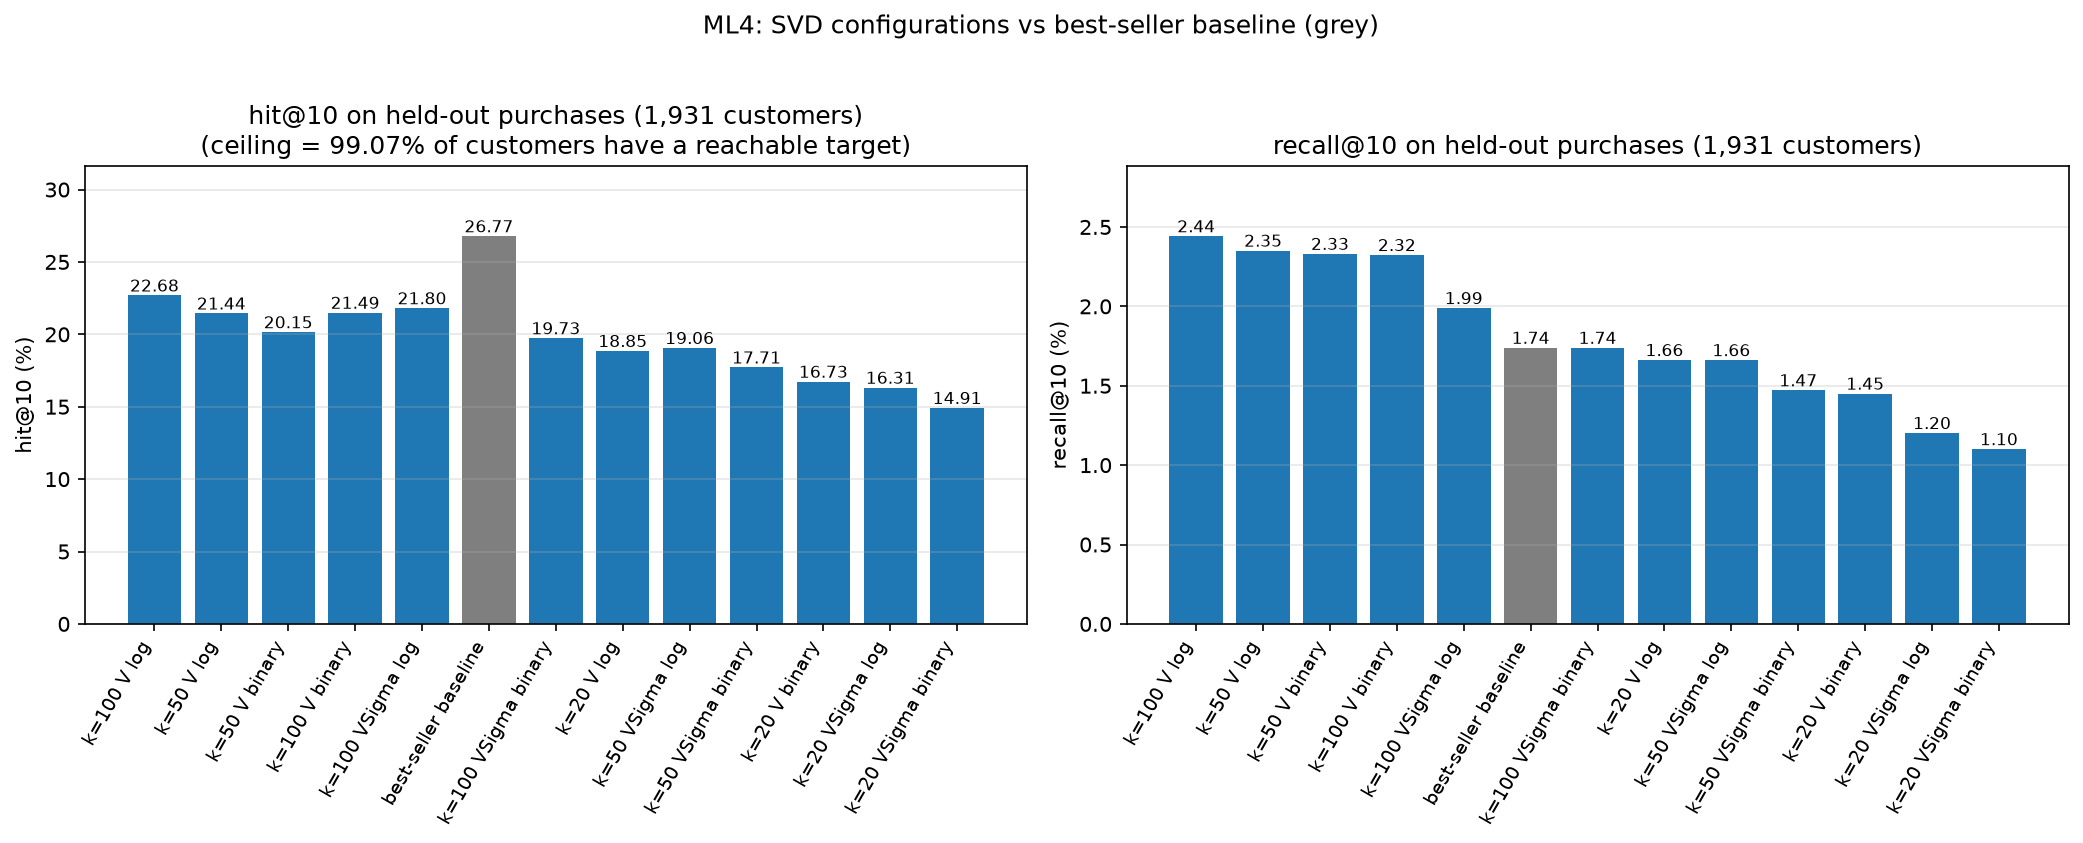

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=False)
labels = table["config"].str.replace("SVD ", "", regex=False).tolist()
colors = ["tab:gray" if c == "best-seller baseline" else "tab:blue" for c in table["config"]]
x = np.arange(len(table))
for ax, metric in zip(axes, ("hit@10", "recall@10")):
    vals = table[metric].to_numpy()
    bars = ax.bar(x, vals, color=colors)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=9)
    ax.set_ylabel(f"{metric} (%)")
    title = f"{metric} on held-out purchases ({ev.n_eval:,} customers)"
    if metric == "hit@10":
        title += f"\n(ceiling = {ev.ceiling_pct:.2f}% of customers have a reachable target)"
    ax.set_title(title)
    ax.grid(True, axis="y", alpha=0.3)
    ax.set_ylim(0, vals.max() * 1.18)
    for b, v in zip(bars, vals):
        ax.annotate(f"{v:.2f}", (b.get_x() + b.get_width() / 2, v), ha="center", va="bottom", fontsize=8)
fig.suptitle("ML4: SVD configurations vs best-seller baseline (grey)", y=1.02)
fig.tight_layout()
fig_path = FIG_DIR / "ml4_results.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.close(fig)
print("saved ->", fig_path.relative_to(ROOT))
from IPython.display import Image, display
display(Image(filename=str(fig_path)))

## 4. Paired bootstrap: reference SVD config vs baseline

1,000 resamples of the 1,931 customers (seed 42), difference in hit@10 and recall@10 in percentage points
(SVD − baseline). Positive means SVD is better.

In [7]:
boot = paired_bootstrap(per_cust[best_name], base_pc, n_boot=1000, seed=42)
boot.insert(0, "comparison", f"{best_name} minus baseline")
print(boot.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

                    comparison    metric  mean_diff_pp  ci95_low_pp  ci95_high_pp  share_resamples_diff_gt_0  n_customers  n_boot
SVD k=100 V log minus baseline    hit@10        -4.091       -6.525        -1.605                      0.000         1931    1000
SVD k=100 V log minus baseline recall@10         0.702        0.208         1.164                      1.000         1931    1000


## 5. Breakdowns

Computed for two SVD configurations: the **reference** config (highest recall@10 in the grid, k=100 V log) and the
**final** config recorded in `decision_log.md` (k=50 V log, chosen for the < 5 MB factor target), both against the baseline.

### 5a. By customer history size (distinct products bought in train)

In [8]:
FINAL_NAME = "SVD k=50 V log"          # final config per decision_log.md
assert FINAL_NAME in per_cust, FINAL_NAME
breakdown_configs = {best_name: per_cust[best_name], FINAL_NAME: per_cust[FINAL_NAME], "best-seller baseline": base_pc}

sizes = history_sizes(A_log, ev)
print("evaluation customers by history size:", dict(zip(*np.unique(pd.cut(sizes, [0, 10, 30, 100, np.inf]).astype(str), return_counts=True))))
hist = breakdown_by_history(sizes, breakdown_configs, HISTORY_BUCKETS)
print(hist.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

print(f"\nlight buyers (1-10 products) side by side:")
lb = hist[hist["history_bucket"] == "1-10"].set_index("config")
for name in breakdown_configs:
    print(f"  {name:<22} hit@10 {lb.loc[name, 'hit@10']:6.2f}%   recall@10 {lb.loc[name, 'recall@10']:6.2f}%")

evaluation customers by history size: {'(0.0, 10.0]': np.int64(94), '(10.0, 30.0]': np.int64(298), '(100.0, inf]': np.int64(810), '(30.0, 100.0]': np.int64(729)}
              config history_bucket  n_customers  hit@10  recall@10
     SVD k=100 V log           1-10           94   31.91      10.86
     SVD k=100 V log          11-30          298   25.17       2.83
     SVD k=100 V log         31-100          729   24.14       2.47
     SVD k=100 V log           101+          810   19.38       1.30
      SVD k=50 V log           1-10           94   25.53       8.34
      SVD k=50 V log          11-30          298   25.50       3.39
      SVD k=50 V log         31-100          729   23.18       2.39
      SVD k=50 V log           101+          810   17.90       1.24
best-seller baseline           1-10           94   22.34       2.40
best-seller baseline          11-30          298   29.53       2.56
best-seller baseline         31-100          729   27.16       1.93
best-seller baseline  

### 5b. Rare-product hits

Of each config's hits (top-10 ∩ targets pairs), how many are products with 10–20 train customers? Compared
with the share of recommendations and of in-matrix targets in that band.

In [9]:
rare_rows = []
for name in breakdown_configs:
    d = rare_product_hits(all_recs[name], ev, product_index, band=RARE_BAND, n=TOP_N)
    rare_rows.append({"config": name, **d})
rare = pd.DataFrame(rare_rows)
print(rare.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

              config  total_hits  hits_on_products_with_10-20_customers  share_of_hits_pct  share_of_recommendations_in_band_pct  share_of_in_matrix_targets_in_band_pct
     SVD k=100 V log         658                                      7               1.06                                  6.26                                    3.95
      SVD k=50 V log         609                                      7               1.15                                  4.35                                    3.95
best-seller baseline         699                                      0               0.00                                  0.00                                    3.95


### Save breakdowns

`reports/ml4_breakdowns.csv` in long format (`section, config, group, metric, value`): history buckets and the
rare-product check for the reference config, the final config and the baseline.

In [10]:
hist_long = hist.assign(section="history_bucket").rename(columns={"history_bucket": "group"})
rare_long = rare.melt(id_vars="config", var_name="group", value_name="value").assign(section="rare_product_hits")
hist_long = hist_long.melt(id_vars=["section", "config", "group"], var_name="metric", value_name="value")
rare_long["metric"] = rare_long["group"]
rare_long["group"] = f"n_customers {RARE_BAND[0]}-{RARE_BAND[1]}"
breakdowns = pd.concat(
    [hist_long[["section", "config", "group", "metric", "value"]], rare_long[["section", "config", "group", "metric", "value"]]],
    ignore_index=True,
)
breakdowns.to_csv(REPORTS / "ml4_breakdowns.csv", index=False)
print(f"saved -> reports/ml4_breakdowns.csv ({len(breakdowns)} rows)")

saved -> reports/ml4_breakdowns.csv (51 rows)


## 6. Timing of the nightly job

fit + item-neighbour precompute + score **all** 5,471 customers; 3 repeats, median reported, for the reference config
(k=100) and the final config (k=50). J1 target: < 60 s.

In [11]:
timings = {}
for name in (best_name, FINAL_NAME):
    row = results.set_index("config").loc[name]
    t = time_nightly(A_log, A_binary, product_index, k=int(row["k"]), weighting=row["weighting"], row_source=row["row"], repeats=3, n=TOP_N)
    timings[name] = t
    med = t.median(numeric_only=True)
    print(f"=== {name} ===")
    print(t.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
    print(f"median of 3: fit {med['fit_s']:.3f}s + neighbours {med['neighbors_s']:.3f}s + score all {med['score_all_s']:.3f}s "
          f"= {med['total_s']:.3f}s   [J1 target < 60 s]\n")

=== SVD k=100 V log ===
 repeat  fit_s  neighbors_s  score_all_s  total_s
      1  0.196        0.105        0.175    0.476
      2  0.206        0.108        0.174    0.488
      3  0.198        0.105        0.169    0.471
median of 3: fit 0.198s + neighbours 0.105s + score all 0.174s = 0.476s   [J1 target < 60 s]



=== SVD k=50 V log ===
 repeat  fit_s  neighbors_s  score_all_s  total_s
      1  0.104        0.100        0.160    0.365
      2  0.105        0.105        0.162    0.371
      3  0.105        0.103        0.165    0.373
median of 3: fit 0.105s + neighbours 0.103s + score all 0.162s = 0.371s   [J1 target < 60 s]



## Stop here

No configuration is chosen in this notebook. `reports/ml4_results.csv`, `reports/ml4_breakdowns.csv` and
`reports/figures/ml4_results.png` are the inputs to that decision.